In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_excel('PJMW_MW_Hourly.xlsx')
df

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930
...,...,...
143201,2018-01-01 20:00:00,8401
143202,2018-01-01 21:00:00,8373
143203,2018-01-01 22:00:00,8238
143204,2018-01-01 23:00:00,7958


In [11]:
df.head()

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930


In [13]:
df.shape

(143206, 2)

In [14]:
df.columns

Index(['Datetime', 'PJMW_MW'], dtype='object')

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB


In [16]:
df.describe()

,Datetime,PJMW_MW
count,143206,143206.000000
mean,2010-06-02 03:39:50.656816128,5602.375089
min,2002-04-01 01:00:00,487.000000
25%,2006-05-02 03:15:00,4907.000000
50%,2010-06-02 04:30:00,5530.000000
75%,2014-07-03 06:45:00,6252.000000
max,2018-08-03 00:00:00,9594.000000
std,NaN,979.142872


In [17]:
print("Start Date:", df['Datetime'].min())
print("End Date:", df['Datetime'].max())

Start Date: 2002-04-01 01:00:00
End Date: 2018-08-03 00:00:00


In [18]:
df['Datetime'] = pd.to_datetime(df['Datetime'])

In [19]:
df['Datetime'].dtype

dtype('<M8[ns]')

In [20]:
df.isnull().sum()

Datetime    0
PJMW_MW     0
dtype: int64

In [21]:
df.duplicated().sum()

np.int64(0)

In [72]:
(df['PJMW_MW'] < 0).sum()

np.int64(0)

In [24]:
df = df.sort_values('Datetime')
df = df.reset_index(drop=True)

In [68]:
df['Year'] = df['Datetime'].dt.year
df[['Datetime', 'Year']].head()

,Datetime,Year
0,2002-04-01 01:00:00,2002
1,2002-04-01 02:00:00,2002
2,2002-04-01 03:00:00,2002
3,2002-04-01 04:00:00,2002
4,2002-04-01 05:00:00,2002


In [69]:
df['Month'] = df['Datetime'].dt.month
df[['Datetime', 'Month']].head()

,Datetime,Month
0,2002-04-01 01:00:00,4
1,2002-04-01 02:00:00,4
2,2002-04-01 03:00:00,4
3,2002-04-01 04:00:00,4
4,2002-04-01 05:00:00,4


In [67]:
df['Month_Name'] = df['Datetime'].dt.month_name()
df[['Datetime', 'Month_Name']].head()

,Datetime,Month_Name
0,2002-04-01 01:00:00,April
1,2002-04-01 02:00:00,April
2,2002-04-01 03:00:00,April
3,2002-04-01 04:00:00,April
4,2002-04-01 05:00:00,April


In [70]:
df['Hour'] = df['Datetime'].dt.hour
df[['Datetime', 'Hour']].head()

,Datetime,Hour
0,2002-04-01 01:00:00,1
1,2002-04-01 02:00:00,2
2,2002-04-01 03:00:00,3
3,2002-04-01 04:00:00,4
4,2002-04-01 05:00:00,5


In [71]:
df['DayOfWeek'] = df['Datetime'].dt.day_name()
df[['Datetime', 'DayOfWeek']].head()

,Datetime,DayOfWeek
0,2002-04-01 01:00:00,Monday
1,2002-04-01 02:00:00,Monday
2,2002-04-01 03:00:00,Monday
3,2002-04-01 04:00:00,Monday
4,2002-04-01 05:00:00,Monday


In [30]:
df['Date'] = df['Datetime'].dt.date

In [31]:
df.head()

,Datetime,PJMW_MW,Year,Month,Month_Name,Hour,DayOfWeek,Date
0,2002-04-01 01:00:00,4374,2002,4,April,1,Monday,2002-04-01
1,2002-04-01 02:00:00,4306,2002,4,April,2,Monday,2002-04-01
2,2002-04-01 03:00:00,4322,2002,4,April,3,Monday,2002-04-01
3,2002-04-01 04:00:00,4359,2002,4,April,4,Monday,2002-04-01
4,2002-04-01 05:00:00,4436,2002,4,April,5,Monday,2002-04-01


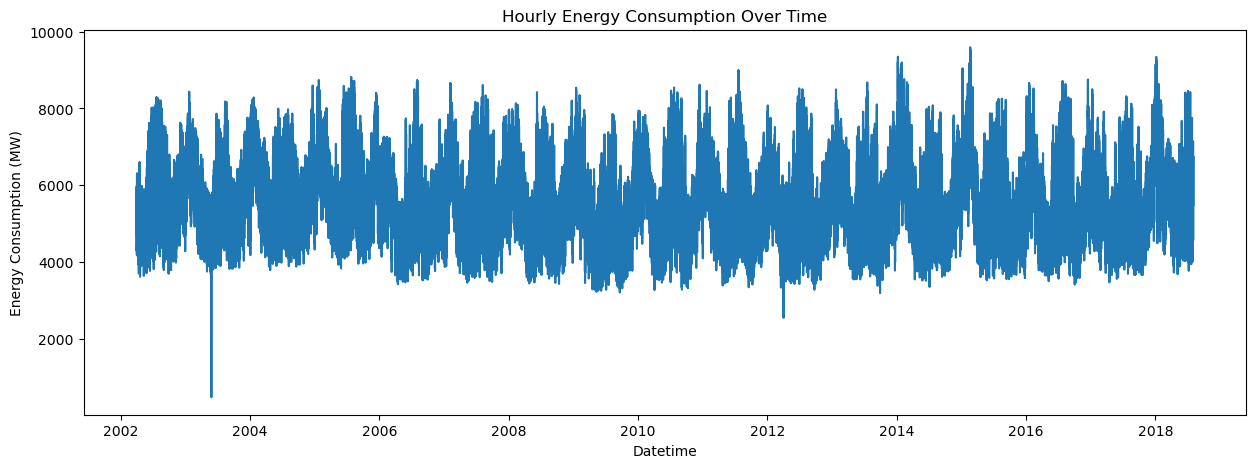

In [32]:
plt.figure(figsize=(15,5))
plt.plot(df['Datetime'], df['PJMW_MW'])
plt.title('Hourly Energy Consumption Over Time')
plt.xlabel('Datetime')
plt.ylabel('Energy Consumption (MW)')
plt.show()

In [33]:
daily_avg = df.groupby('Date')['PJMW_MW'].mean()

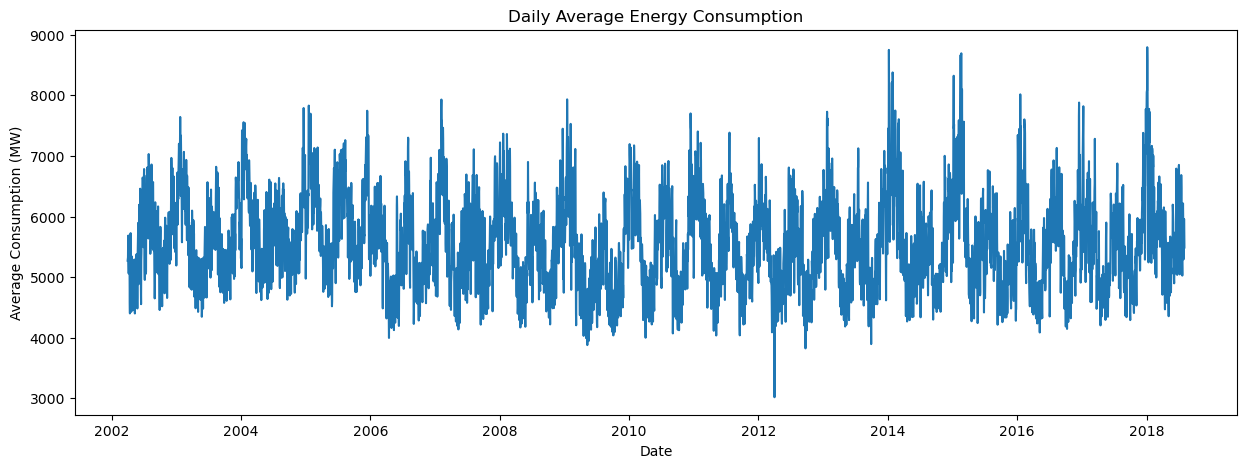

In [34]:
plt.figure(figsize=(15,5))
plt.plot(daily_avg.index, daily_avg.values)
plt.title('Daily Average Energy Consumption')
plt.xlabel('Date')
plt.ylabel('Average Consumption (MW)')
plt.show()

In [35]:
hourly_avg = df.groupby('Hour')['PJMW_MW'].mean()
print(hourly_avg)

Hour
0     5230.368359
1     4940.489276
2     4779.152349
3     4697.121996
4     4672.537366
5     4734.933479
6     4958.209450
7     5323.434316
8     5571.168398
9     5708.667058
10    5818.219169
11    5904.120476
12    5947.523794
13    5959.946716
14    5970.935824
15    5953.164712
16    5957.636394
17    6031.231233
18    6158.806803
19    6199.285355
20    6183.568365
21    6152.210121
22    5982.300436
23    5618.226206
Name: PJMW_MW, dtype: float64


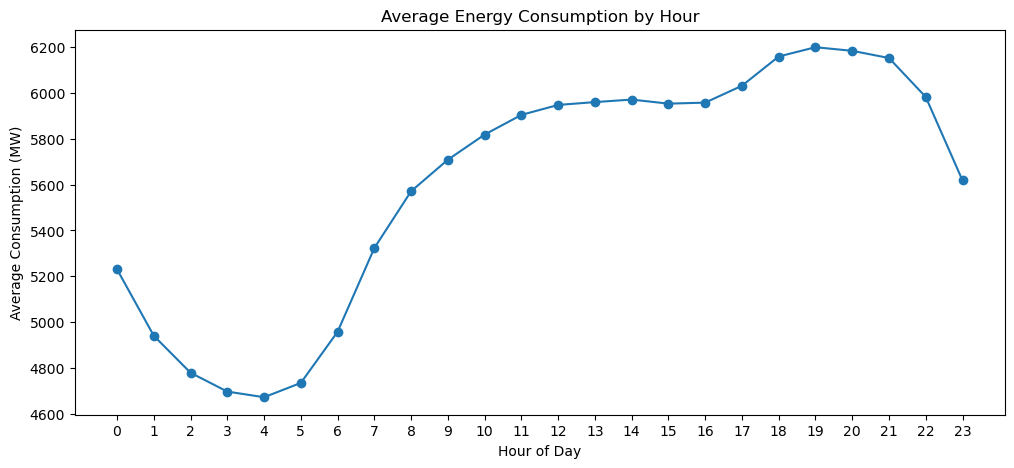

In [36]:
plt.figure(figsize=(12,5))
plt.plot(hourly_avg.index, hourly_avg.values, marker='o')
plt.title('Average Energy Consumption by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Consumption (MW)')
plt.xticks(range(24))
plt.show()

In [37]:
hourly_avg.idxmin()

np.int32(4)

In [38]:
hourly_avg.idxmax()

np.int32(19)

In [39]:
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]
day_avg = df.groupby('DayOfWeek')['PJMW_MW'].mean()
day_avg = day_avg.reindex(day_order)
print(day_avg)

DayOfWeek
Monday       5700.518783
Tuesday      5801.076837
Wednesday    5802.370701
Thursday     5780.841051
Friday       5686.839202
Saturday     5293.999413
Sunday       5149.638300
Name: PJMW_MW, dtype: float64


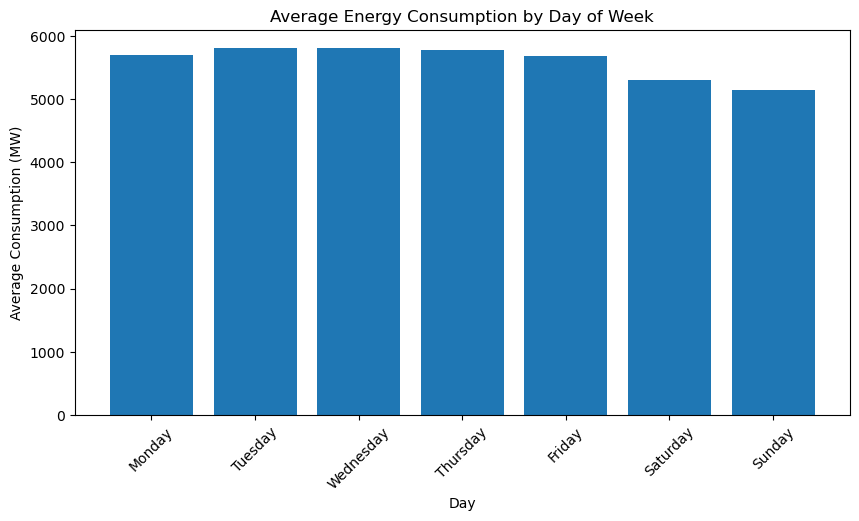

In [40]:
plt.figure(figsize=(10,5))
plt.bar(day_avg.index, day_avg.values)
plt.title('Average Energy Consumption by Day of Week')
plt.xlabel('Day')
plt.ylabel('Average Consumption (MW)')
plt.xticks(rotation=45)
plt.show()

In [41]:
df['Day_Type'] = np.where(
    df['Datetime'].dt.dayofweek < 5,
    'Weekday',
    'Weekend'
)

In [42]:
day_type_avg = df.groupby('Day_Type')['PJMW_MW'].mean()
print(day_type_avg)

Day_Type
Weekday    5754.345669
Weekend    5221.863008
Name: PJMW_MW, dtype: float64


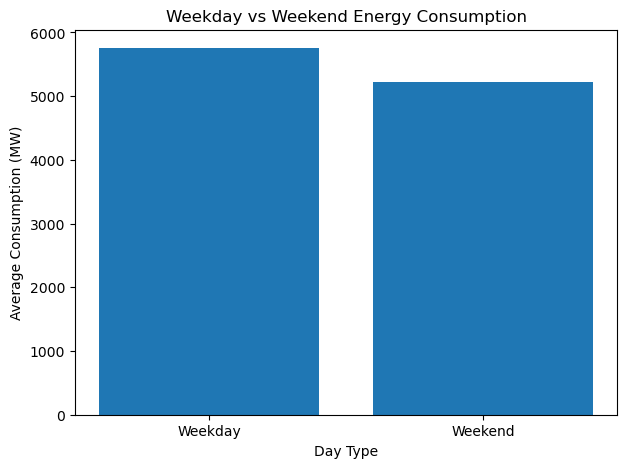

In [43]:
plt.figure(figsize=(7,5))
plt.bar(day_type_avg.index, day_type_avg.values)
plt.title('Weekday vs Weekend Energy Consumption')
plt.xlabel('Day Type')
plt.ylabel('Average Consumption (MW)')
plt.show()

In [44]:
monthly_avg = df.groupby('Month')['PJMW_MW'].mean()
print(monthly_avg)

Month
1     6447.667759
2     6296.808813
3     5654.097376
4     5022.310855
5     5015.845746
6     5516.756046
7     5861.537081
8     5822.142809
9     5205.872049
10    4997.642155
11    5403.630372
12    6064.431236
Name: PJMW_MW, dtype: float64


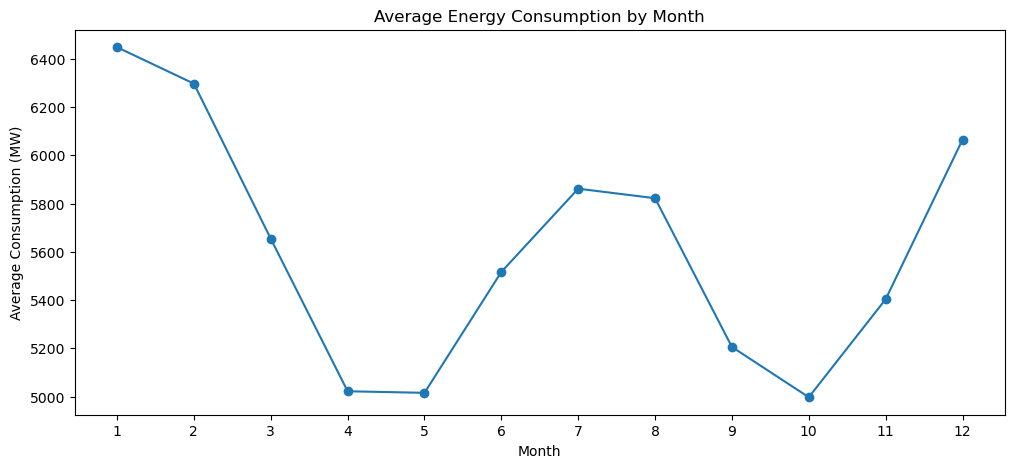

In [45]:
plt.figure(figsize=(12,5))
plt.plot(monthly_avg.index, monthly_avg.values, marker='o')
plt.title('Average Energy Consumption by Month')
plt.xlabel('Month')
plt.ylabel('Average Consumption (MW)')
plt.xticks(range(1,13))
plt.show()

In [47]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

In [48]:
df['Season'] = df['Month'].apply(get_season)

In [49]:
df[['Month', 'Season']].drop_duplicates().sort_values('Month')

,Month,Season
6597,1,Winter
7341,2,Winter
8013,3,Spring
0,4,Spring
718,5,Spring
1462,6,Summer
2182,7,Summer
2926,8,Summer
3670,9,Fall
4390,10,Fall


In [50]:
season_avg = df.groupby('Season')['PJMW_MW'].mean()
print(season_avg)

Season
Fall      5200.143147
Spring    5224.394790
Summer    5734.206129
Winter    6268.813851
Name: PJMW_MW, dtype: float64


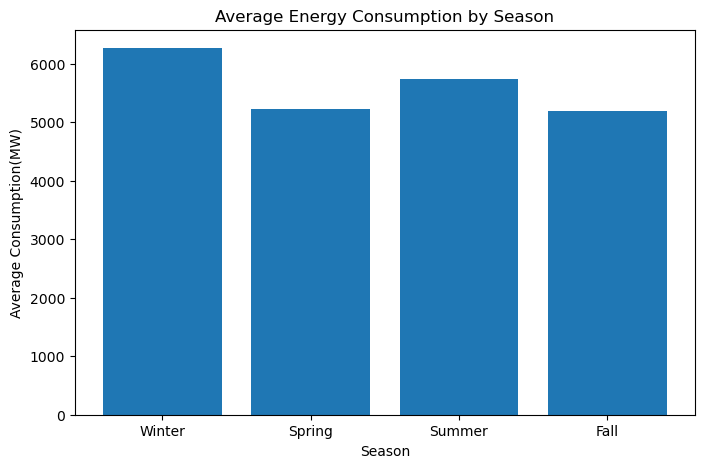

In [73]:
season_order=['Winter','Spring','Summer','Fall']
season_avg=season_avg.reindex(season_order)
plt.figure(figsize=(8,5))
plt.bar(season_avg.index, season_avg.values)
plt.title('Average Energy Consumption by Season')
plt.xlabel('Season')
plt.ylabel('Average Consumption(MW)')
plt.show()

In [52]:
summer = df[df['Season'] == 'Summer']
winter = df[df['Season'] == 'Winter']

In [53]:
print("Summer Average:",
      summer['PJMW_MW'].mean())
print("Winter Average:",
      winter['PJMW_MW'].mean())

Summer Average: 5734.206129041014
Winter Average: 6268.813850815178


In [54]:
summer_hourly = summer.groupby('Hour')['PJMW_MW'].mean()
winter_hourly = winter.groupby('Hour')['PJMW_MW'].mean()

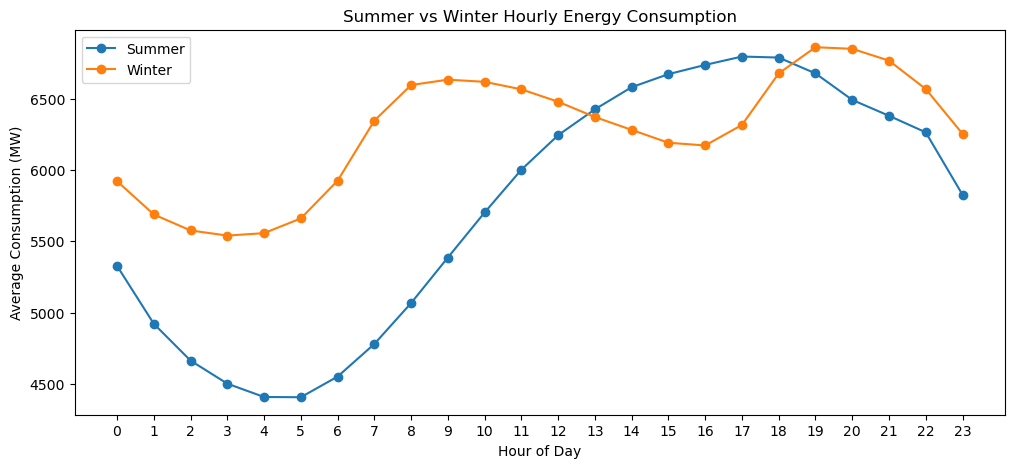

In [55]:
plt.figure(figsize=(12,5))
plt.plot(
    summer_hourly.index,
    summer_hourly.values,
    marker='o',
    label='Summer'
)
plt.plot(
    winter_hourly.index,
    winter_hourly.values,
    marker='o',
    label='Winter'
)
plt.title('Summer vs Winter Hourly Energy Consumption')
plt.xlabel('Hour of Day')
plt.ylabel('Average Consumption (MW)')
plt.xticks(range(24))
plt.legend()
plt.show()

In [56]:
yearly_avg = df.groupby('Year')['PJMW_MW'].mean()
print(yearly_avg)

Year
2002    5621.663180
2003    5700.628226
2004    5866.616602
2005    6038.406029
2006    5425.448847
2007    5635.396780
2008    5530.132544
2009    5290.557433
2010    5573.025351
2011    5509.640215
2012    5395.010818
2013    5556.783626
2014    5656.334132
2015    5620.985616
2016    5577.929531
2017    5500.184361
2018    5848.157516
Name: PJMW_MW, dtype: float64


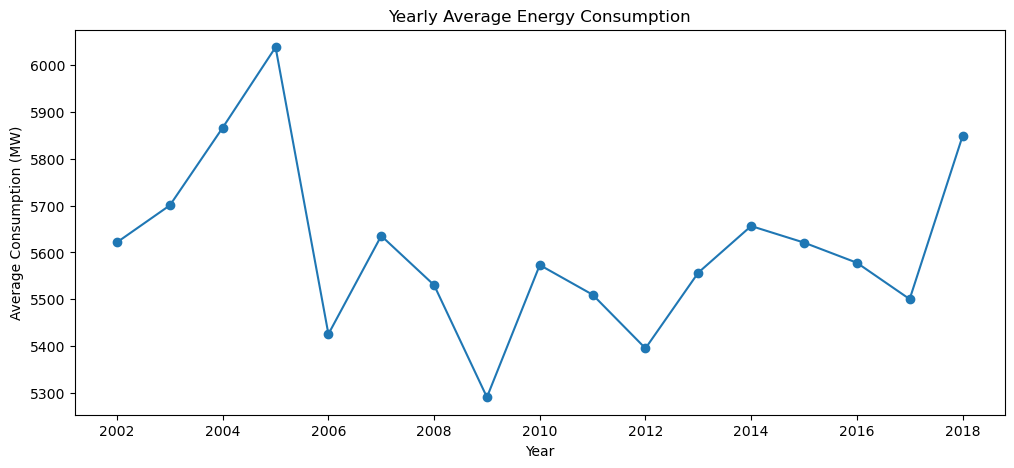

In [57]:
plt.figure(figsize=(12,5))
plt.plot(
    yearly_avg.index,
    yearly_avg.values,
    marker='o'
)
plt.title('Yearly Average Energy Consumption')
plt.xlabel('Year')
plt.ylabel('Average Consumption (MW)')
plt.show()

In [60]:
last_date = df['Datetime'].max()
print(last_date)

2018-08-03 00:00:00


In [61]:
test_start_date = last_date - pd.Timedelta(days=365)
print(test_start_date)

2017-08-03 00:00:00


In [74]:
train = df[df['Datetime'] < test_start_date]
test = df[df['Datetime'] >= test_start_date]

In [63]:
print("Train Shape:", train.shape)
print("Test Shape:", test.shape)

Train Shape: (134445, 10)
Test Shape: (8761, 10)


In [64]:
print(
    "Train:",
    train['Datetime'].min(),
    "to",
    train['Datetime'].max()
)
print(
    "Test:",
    test['Datetime'].min(),
    "to",
    test['Datetime'].max()
)

Train: 2002-04-01 01:00:00 to 2017-08-02 23:00:00
Test: 2017-08-03 00:00:00 to 2018-08-03 00:00:00


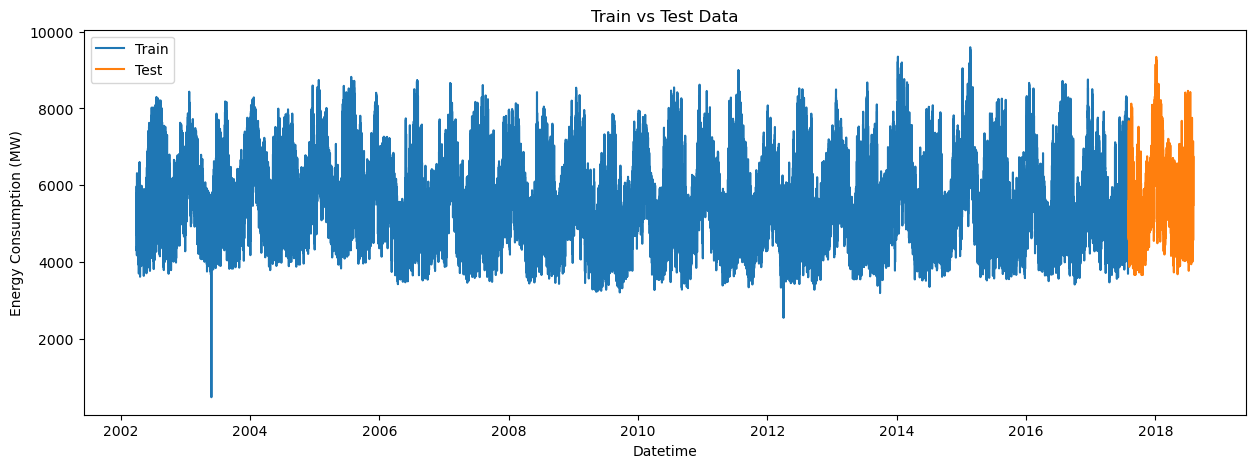

In [65]:
plt.figure(figsize=(15,5))
plt.plot(
    train['Datetime'],
    train['PJMW_MW'],
    label='Train'
)
plt.plot(
    test['Datetime'],
    test['PJMW_MW'],
    label='Test'
)
plt.title('Train vs Test Data')
plt.xlabel('Datetime')
plt.ylabel('Energy Consumption (MW)')
plt.legend()
plt.show()

In [66]:
summary = pd.DataFrame({
    'Analysis': [
        'Hourly Pattern',
        'Weekday vs Weekend',
        'Monthly Pattern',
        'Seasonal Pattern',
        'Summer vs Winter',
        'Long-Term Trend'
    ],
    'Metric': [
        hourly_avg.mean(),
        day_type_avg.mean(),
        monthly_avg.mean(),
        season_avg.mean(),
        summer['PJMW_MW'].mean(),
        yearly_avg.mean()
    ]
})

,Analysis,Metric
0,Hourly Pattern,5602.219069
1,Weekday vs Weekend,5488.104338
2,Monthly Pattern,5609.061858
3,Seasonal Pattern,5606.889479
4,Summer vs Winter,5734.206129
5,Long-Term Trend,5608.641224
